Shape: (150, 4) -> (150, 2)
Explained variance ratio: [0.72962445 0.22850762] Total: 0.9581320720000164


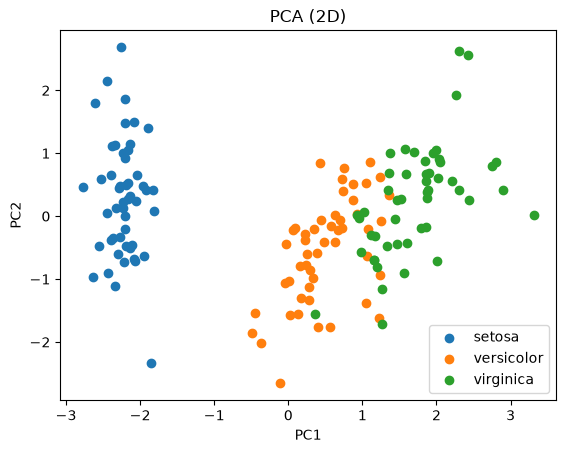

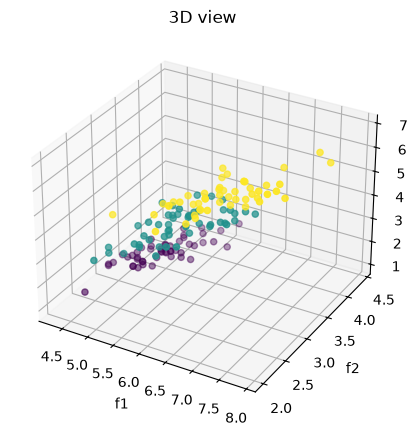

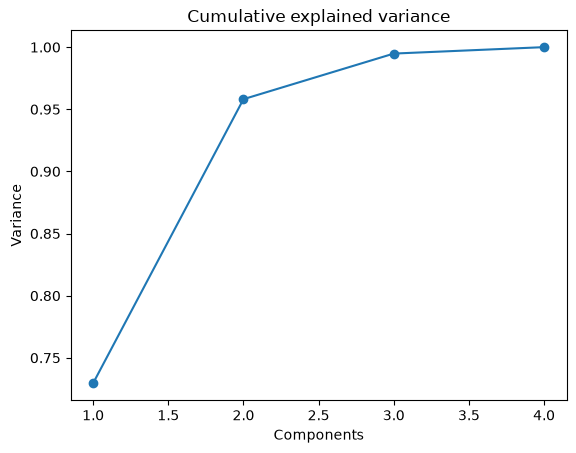

In [1]:
# ===================== REVISION / ONE-SHOT: PCA =====================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1) Load + scale (PCA is variance based, so scale first)
iris = load_iris()
X, y = iris.data, iris.target
X_scaled = StandardScaler().fit_transform(X)

# 2) PCA to 2D
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print("Shape:", X.shape, "->", X_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_, "Total:", pca.explained_variance_ratio_.sum())

# 3) 2D scatter, one colour per class, with legend
for i, name in enumerate(iris.target_names):
    plt.scatter(X_pca[y == i, 0], X_pca[y == i, 1], label=name)
plt.title("PCA (2D)"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend(); plt.show()

# 4) 3D scatter pattern
fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=y)
ax.set_xlabel("f1"); ax.set_ylabel("f2"); ax.set_zlabel("f3"); ax.set_title("3D view"); plt.show()

# 5) Scree plot: PCA() with all components
pca_all = PCA().fit(X_scaled)
plt.plot(range(1, 5), np.cumsum(pca_all.explained_variance_ratio_), marker="o")
plt.title("Cumulative explained variance"); plt.xlabel("Components"); plt.ylabel("Variance"); plt.show()

# ---------------- VIVA NOTES ----------------
# PCA = unsupervised; finds new orthogonal axes (principal components) of max variance.
# Components = eigenvectors of covariance matrix, explained variance = eigenvalues.
# Always StandardScaler first, else large-unit features dominate.
# explained_variance_ratio_ tells how much information each PC keeps; choose k for ~90-95%.
# n_components <= min(n_samples, n_features). PCA ignores labels (LDA uses them).
# Read plot: well separated colour groups = PCs keep class structure.

### Q27

Write a Python program to apply Principal Component Analysis (PCA) on the Iris dataset and reduce its dimensionality to 2 dimensions. You should use sklearn's PCA implementation. After reducing the dimensions, visualize the transformed data in a 2D scatter plot, coloring the points based on their respective classes.

Dataset Description:
- The Iris dataset consists of 150 samples with 4 features.
- The target variable is categorical with three classes (Setosa, Versicolor, Virginica).

Instructions:
- Import the necessary libraries.
- Load the Iris dataset from sklearn.datasets.
- Separate the features and the target variable.
- Standardize the features (mean = 0, variance = 1).
- Apply PCA to reduce the dimensionality of the dataset to 2 dimensions.

Visualize the transformed data in a 2D scatter plot, using different colors for each class.

In [2]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [3]:
# Load and separate features / target
iris = load_iris()
X = iris.data
y = iris.target
print("X shape:", X.shape)

X shape: (150, 4)


In [4]:
# Standardize (mean 0, variance 1)
X_scaled = StandardScaler().fit_transform(X)
print("Means:", X_scaled.mean(axis=0).round(2), "| Std:", X_scaled.std(axis=0).round(2))

Means: [-0. -0. -0. -0.] | Std: [1. 1. 1. 1.]


In [5]:
# PCA to 2 dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print("New shape:", X_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3))

New shape: (150, 2)
Explained variance ratio: [0.73  0.229]


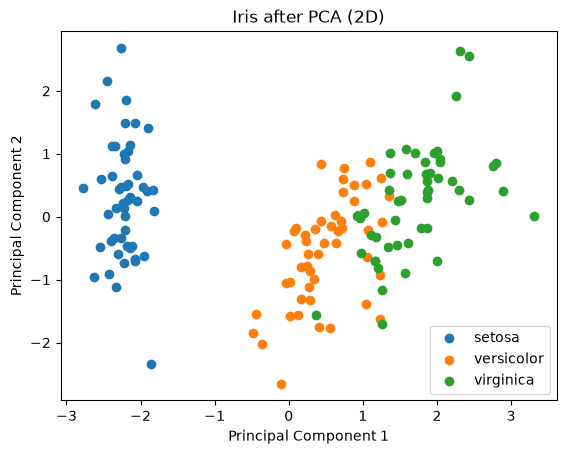

In [6]:
# Scatter plot coloured by class
for i, name in enumerate(iris.target_names):
    plt.scatter(X_pca[y == i, 0], X_pca[y == i, 1], label=name)
plt.title("Iris after PCA (2D)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.show()

### Q30

Create a synthetic dataset using make_blobs with the following specifications:
- The dataset should have 4 features and 4 centers (clusters).
- Initialize the PCA object with n_components=3 to reduce the dataset to 3 dimensions.
- Use Matplotlib to plot the original 4D dataset in a 3D scatter plot and the PCA-reduced 3D dataset in another 3D scatter plot side by side.

Instructions:
- Import the necessary libraries (numpy, matplotlib, and sklearn).
- Generate the synthetic dataset using make_blobs.
- Apply PCA to reduce the dataset to 3 dimensions.
- Create a figure with two subplots:
- The first subplot should display the original 3D representation of the dataset (you can use any three of the four features for this plot).
- The second subplot should display the PCA-reduced 3D dataset.
- Ensure that the points in both plots are color-coded based on their respective cluster labels.

Add appropriate titles and labels to the plots for clarity.

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.decomposition import PCA

In [8]:
# 4 features, 4 centers
X, y = make_blobs(n_samples=300, n_features=4, centers=4, random_state=42)
print("Original shape:", X.shape)

Original shape: (300, 4)


In [9]:
# PCA to 3 dimensions
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X)
print("Reduced shape:", X_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3))

Reduced shape: (300, 3)
Explained variance ratio: [0.463 0.38  0.15 ]


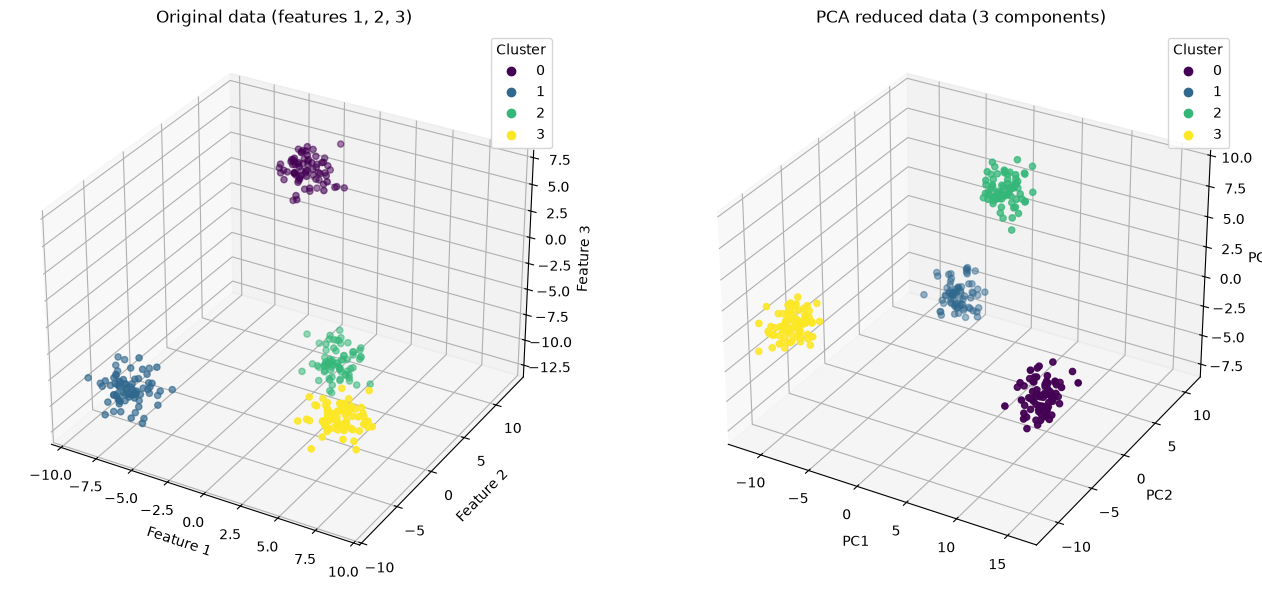

In [10]:
# Side by side 3D plots
fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1, projection="3d")
sc = ax1.scatter(X[:, 0], X[:, 1], X[:, 2], c=y, cmap="viridis")
ax1.set_title("Original data (features 1, 2, 3)")
ax1.set_xlabel("Feature 1")
ax1.set_ylabel("Feature 2")
ax1.set_zlabel("Feature 3")
ax1.legend(*sc.legend_elements(), title="Cluster")

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
sc = ax2.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c=y, cmap="viridis")
ax2.set_title("PCA reduced data (3 components)")
ax2.set_xlabel("PC1")
ax2.set_ylabel("PC2")
ax2.set_zlabel("PC3")
ax2.legend(*sc.legend_elements(), title="Cluster")

plt.tight_layout()
plt.show()

### Q33

Apply Principal Component Analysis (PCA) to the Iris dataset to reduce its dimensionality from 4 to 2 dimensions. You will visualize the PCA-reduced dataset in a 2D scatter plot using Matplotlib.

instructions:
- Load the Iris dataset
- Briefly explore the dataset to understand its structure. Print the shape of the dataset and the first few rows to get an overview of the features and target variable.
- Initialize the PCA object to reduce the dataset to 2 dimensions.
- Fit the PCA model to the Iris dataset and transform the dataset
- Use Matplotlib to create a scatter plot of the PCA-reduced dataset.
- Color the points based on their respective species (Setosa, Versicolor, Virginica) to visualize how well the PCA has separated the different classes.
- Add appropriate titles and labels to the axes of the plot.
- Include a legend to indicate which colors correspond to which species.

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA

In [12]:
# Load and explore
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"] = [iris.target_names[t] for t in iris.target]
print("Shape:", df.shape)
print(df.head())
print(df["species"].value_counts())

Shape: (150, 5)
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [13]:
# PCA to 2 dimensions
X = iris.data
y = iris.target
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
print("Reduced shape:", X_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3))

Reduced shape: (150, 2)
Explained variance ratio: [0.925 0.053]


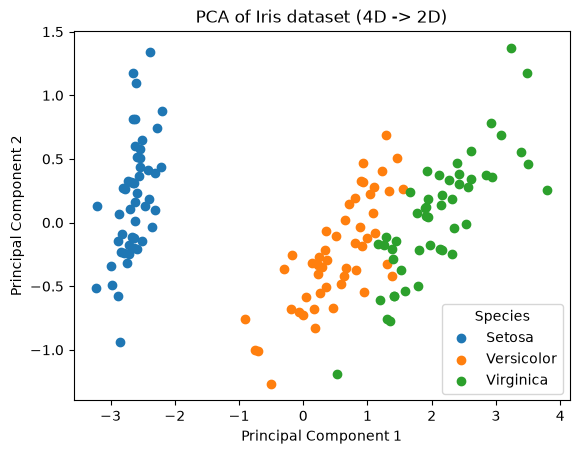

In [14]:
# Scatter plot with legend by species
for i, name in enumerate(iris.target_names):
    plt.scatter(X_pca[y == i, 0], X_pca[y == i, 1], label=name.capitalize())
plt.title("PCA of Iris dataset (4D -> 2D)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Species")
plt.show()

### Q62

Write a python snippet to demonstrate use of PCA on 100 samples with 3 features generated randomly.

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

In [16]:
# 100 random samples, 3 features (feature 3 depends on feature 1 so PCA has something to find)
np.random.seed(42)
f1 = np.random.rand(100)
f2 = np.random.rand(100)
f3 = 2 * f1 + 0.1 * np.random.rand(100)
X = np.column_stack([f1, f2, f3])
print("Original shape:", X.shape)

Original shape: (100, 3)


In [17]:
# PCA to 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
print("Reduced shape:", X_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3))
print("Total variance kept:", round(pca.explained_variance_ratio_.sum(), 3))

Reduced shape: (100, 2)
Explained variance ratio: [0.837 0.162]
Total variance kept: 1.0


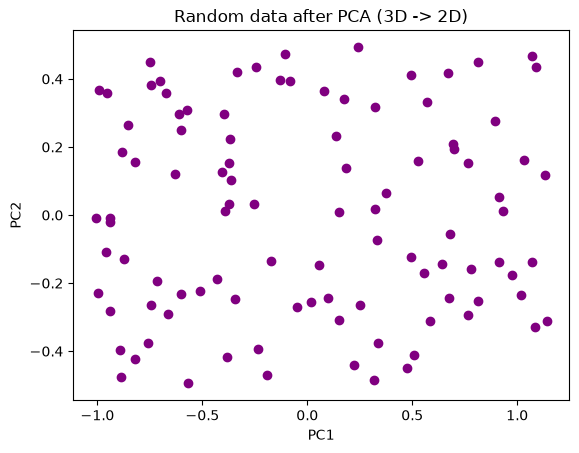

In [18]:
plt.scatter(X_pca[:, 0], X_pca[:, 1], c="purple")
plt.title("Random data after PCA (3D -> 2D)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

### Q63

Write a python snippet to demonstrate use of PCA on dataset of your choice. Also print explained variance of all principle components.

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [20]:
# Wine dataset: 178 samples, 13 features
wine = load_wine()
X = StandardScaler().fit_transform(wine.data)
y = wine.target
print("Shape:", X.shape)

Shape: (178, 13)


In [21]:
# PCA with all components
pca = PCA()
X_pca = pca.fit_transform(X)
for i, (v, r) in enumerate(zip(pca.explained_variance_, pca.explained_variance_ratio_), start=1):
    print(f"PC{i}: explained variance = {v:.3f}, ratio = {r:.3f}")
print("Cumulative:", np.cumsum(pca.explained_variance_ratio_).round(3))

PC1: explained variance = 4.732, ratio = 0.362
PC2: explained variance = 2.511, ratio = 0.192
PC3: explained variance = 1.454, ratio = 0.111
PC4: explained variance = 0.924, ratio = 0.071
PC5: explained variance = 0.858, ratio = 0.066
PC6: explained variance = 0.645, ratio = 0.049
PC7: explained variance = 0.554, ratio = 0.042
PC8: explained variance = 0.350, ratio = 0.027
PC9: explained variance = 0.291, ratio = 0.022
PC10: explained variance = 0.252, ratio = 0.019
PC11: explained variance = 0.227, ratio = 0.017
PC12: explained variance = 0.170, ratio = 0.013
PC13: explained variance = 0.104, ratio = 0.008
Cumulative: [0.362 0.554 0.665 0.736 0.802 0.851 0.893 0.92  0.942 0.962 0.979 0.992
 1.   ]


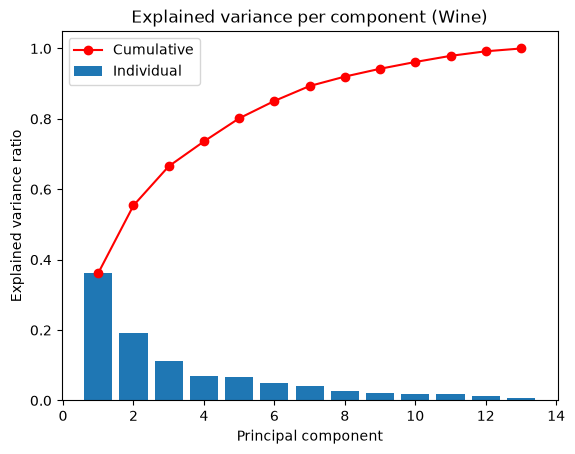

In [22]:
# Scree plot
n = len(pca.explained_variance_ratio_)
plt.bar(range(1, n + 1), pca.explained_variance_ratio_, label="Individual")
plt.plot(range(1, n + 1), np.cumsum(pca.explained_variance_ratio_), marker="o", color="red", label="Cumulative")
plt.title("Explained variance per component (Wine)")
plt.xlabel("Principal component")
plt.ylabel("Explained variance ratio")
plt.legend()
plt.show()

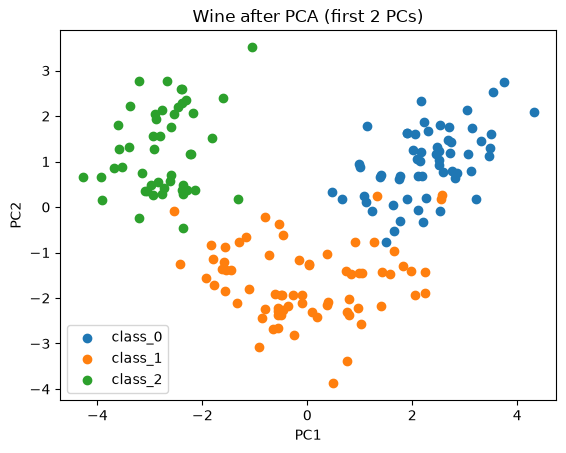

In [23]:
# 2D view with first 2 components
for i, name in enumerate(wine.target_names):
    plt.scatter(X_pca[y == i, 0], X_pca[y == i, 1], label=name)
plt.title("Wine after PCA (first 2 PCs)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()

### Q64

Create synthetic Dataset using make_blobs with 3 features and 3 centers initialize the PCA object with n_components=2 to reduce the dataset to 2 dimensions. use matplotlib to plot the original 3D dataset and the PCA-reduced 2D dataset side by side.

In [24]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.decomposition import PCA

In [25]:
# 3 features, 3 centers
X, y = make_blobs(n_samples=300, n_features=3, centers=3, random_state=42)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
print("Original:", X.shape, "| Reduced:", X_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3))

Original: (300, 3) | Reduced: (300, 2)
Explained variance ratio: [0.891 0.098]


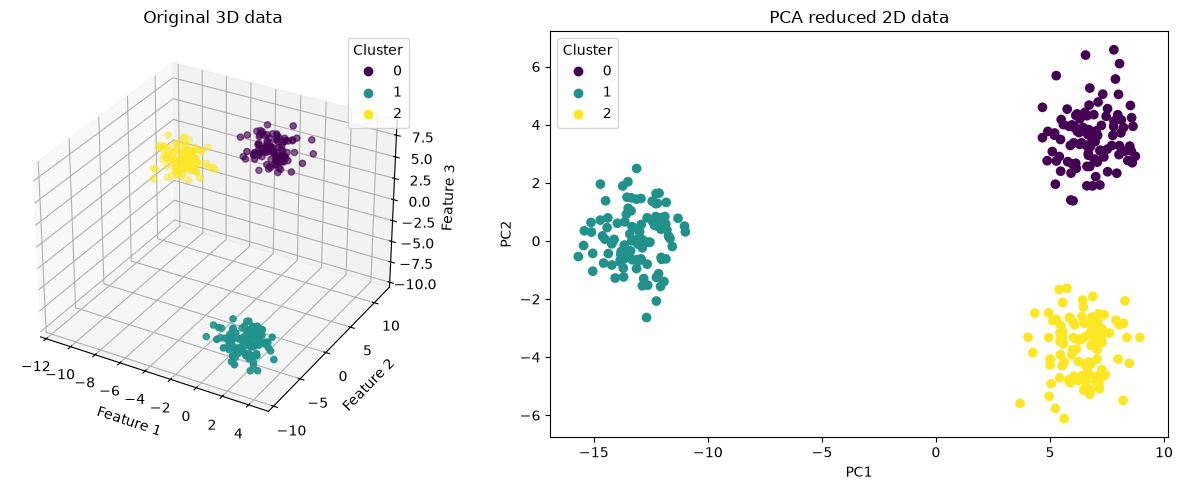

In [26]:
fig = plt.figure(figsize=(13, 5))

ax1 = fig.add_subplot(1, 2, 1, projection="3d")
sc = ax1.scatter(X[:, 0], X[:, 1], X[:, 2], c=y, cmap="viridis")
ax1.set_title("Original 3D data")
ax1.set_xlabel("Feature 1")
ax1.set_ylabel("Feature 2")
ax1.set_zlabel("Feature 3")
ax1.legend(*sc.legend_elements(), title="Cluster")

ax2 = fig.add_subplot(1, 2, 2)
sc = ax2.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="viridis")
ax2.set_title("PCA reduced 2D data")
ax2.set_xlabel("PC1")
ax2.set_ylabel("PC2")
ax2.legend(*sc.legend_elements(), title="Cluster")

plt.tight_layout()
plt.show()

### Q65

Use load_iris from sklearn.datasets to load the Iris dataset. initialize the PCA object with n_components=2 to reduce the dataset to 2. use matplotlib to plot the PCA-reduced dataset in 2D.

In [27]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA

In [28]:
iris = load_iris()
X = iris.data
y = iris.target
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
print("Original:", X.shape, "| Reduced:", X_pca.shape)

Original: (150, 4) | Reduced: (150, 2)


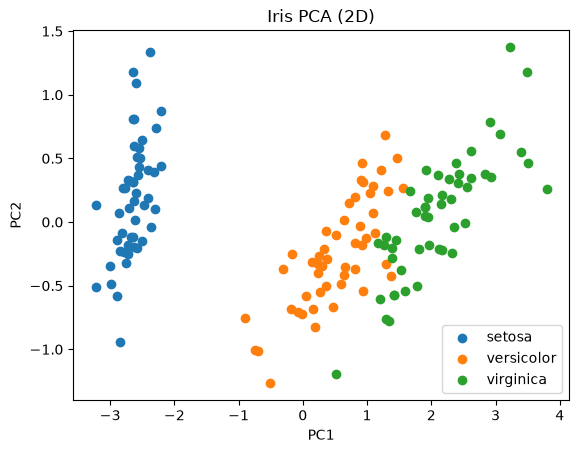

In [29]:
for i, name in enumerate(iris.target_names):
    plt.scatter(X_pca[y == i, 0], X_pca[y == i, 1], label=name)
plt.title("Iris PCA (2D)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()